In [100]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"]=(8,5)

In [101]:
df = pd.read_csv('EDA.xlsx - Raw_Data.csv')
df.head()

,Customer_ID,Age,Gender,City,Employment_Type,Education,Monthly_Income_INR,Years_as_Customer,Satisfaction_Score,Last_Purchase_Amount_INR,Products_Purchased,Payment_Method,Membership_Level,Last_Contact_Date,Churn
0,CUST-0001,34.0,Male,Pune,Salaried,High School,"₹48,887",6.4,7.0,"₹1,619.11",4,Net Banking,Basic,2025-07-23,No
1,CUST-0002,32.0,Male,Hyderabad,Homemaker,High School,"₹2,043",7.9,6.0,"₹7,767.09",5,UPI,Basic,2026-01-03,No
2,CUST-0003,20.0,Female,Mumbai,Retired,Graduate,NaN,4.0,5.0,"₹4,481.84",1,UPI,Silver,24/10/2025,No
3,CUST-0004,49.0,Male,Nagpur,Self-employed,Graduate,NaN,2.0,4.0,₹671.03,2,NaN,Silver,2025-10-04,No
4,CUST-0005,23.0,Female,Pune,Student,NaN,"₹12,821",0.5,6.0,"₹1,601.80",4,Cash,Gold,2026-04-15,Yes


In [102]:
# Convert all numeric columns to numeric datatype

numeric_cols = [
    'Age',
    'Years_as_Customer',
    'Monthly_Income_INR',
    'Last_Purchase_Amount_INR',
    'Satisfaction_Score'
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(',', '', regex=False)
            .str.replace('₹', '', regex=False)
            .str.replace('INR', '', regex=False)
            .str.strip()
        )

        df[col] = pd.to_numeric(df[col], errors='coerce')

        df[col].fillna(df[col].median(), inplace=True)

print(df[numeric_cols].dtypes)

Age                         float64
Years_as_Customer           float64
Monthly_Income_INR          float64
Last_Purchase_Amount_INR    float64
Satisfaction_Score          float64
dtype: object


/tmp/ipykernel_2613/3868268622.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
/tmp/ipykernel_2613/3868268622.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

In [103]:
print(df.shape)

(255, 15)


In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               255 non-null    object 
 1   Age                       255 non-null    float64
 2   Gender                    248 non-null    object 
 3   City                      244 non-null    object 
 4   Employment_Type           248 non-null    object 
 5   Education                 245 non-null    object 
 6   Monthly_Income_INR        255 non-null    float64
 7   Years_as_Customer         255 non-null    float64
 8   Satisfaction_Score        255 non-null    float64
 9   Last_Purchase_Amount_INR  255 non-null    float64
 10  Products_Purchased        255 non-null    int64  
 11  Payment_Method            247 non-null    object 
 12  Membership_Level          255 non-null    object 
 13  Last_Contact_Date         249 non-null    object 
 14  Churn     

In [105]:
df.tail()

,Customer_ID,Age,Gender,City,Employment_Type,Education,Monthly_Income_INR,Years_as_Customer,Satisfaction_Score,Last_Purchase_Amount_INR,Products_Purchased,Payment_Method,Membership_Level,Last_Contact_Date,Churn
250,CUST-0179,23.0,Female,Kolkata,Salaried,Postgraduate,66302.0,2.4,7.0,5749.33,1,Debit Card,Gold,2025-04-11,No
251,CUST-0207,36.0,NaN,Kolkata,Self-employed,Postgraduate,71408.0,3.0,5.0,790.73,6,Debit Card,Silver,30/05/2025,No
252,CUST-0152,47.0,Female,Hyderabad,Salaried,High School,63051.0,14.1,8.0,5118.45,5,UPI,Basic,2026-03-24,No
253,CUST-0183,24.0,Female,Pune,Salaried,Graduate,83089.0,1.9,7.0,4401.26,2,Cash,Gold,NaN,No
254,CUST-0070,40.0,Female,NaN,Salaried,NaN,61494.0,3.5,7.0,11203.80,2,Net Banking,Basic,2025-11-20,Yes


In [106]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'City', 'Employment_Type', 'Education',
       'Monthly_Income_INR', 'Years_as_Customer', 'Satisfaction_Score',
       'Last_Purchase_Amount_INR', 'Products_Purchased', 'Payment_Method',
       'Membership_Level', 'Last_Contact_Date', 'Churn'],
      dtype='object')

In [107]:
df.describe()

,Age,Monthly_Income_INR,Years_as_Customer,Satisfaction_Score,Last_Purchase_Amount_INR,Products_Purchased
count,255.000000,2.550000e+02,255.000000,255.000000,255.000000,255.000000
mean,37.270588,6.679475e+04,3.494118,7.078431,8579.745941,3.956863
std,12.847122,1.887317e+05,2.489744,1.838383,41963.393441,1.938550
min,5.000000,0.000000e+00,0.300000,-2.000000,311.360000,1.000000
25%,30.000000,2.550500e+04,1.800000,6.000000,2028.575000,2.500000
50%,36.000000,4.378200e+04,3.000000,7.000000,3279.925000,4.000000
75%,44.000000,5.985200e+04,4.550000,8.000000,5520.095000,5.000000
max,150.000000,2.500000e+06,15.000000,14.000000,600000.000000,11.000000


In [108]:
#missing values
df.isnull().sum()

,0
Customer_ID,0
Age,0
Gender,7
City,11
Employment_Type,7
Education,10
Monthly_Income_INR,0
Years_as_Customer,0
Satisfaction_Score,0
Last_Purchase_Amount_INR,0


In [109]:
(df.isnull().sum()/len(df))*100

,0
Customer_ID,0.000000
Age,0.000000
Gender,2.745098
City,4.313725
Employment_Type,2.745098
Education,3.921569
Monthly_Income_INR,0.000000
Years_as_Customer,0.000000
Satisfaction_Score,0.000000
Last_Purchase_Amount_INR,0.000000


In [110]:
# duplicate records
print("Duplicate Rows =",df.duplicated().sum())

Duplicate Rows = 5


In [111]:
df=df.drop_duplicates()

In [112]:
df.dtypes

,0
Customer_ID,object
Age,float64
Gender,object
City,object
Employment_Type,object
Education,object
Monthly_Income_INR,float64
Years_as_Customer,float64
Satisfaction_Score,float64
Last_Purchase_Amount_INR,float64


In [113]:
df['Last_Contact_Date']=pd.to_datetime(df['Last_Contact_Date'],errors='coerce')

In [114]:
df.describe(include='all')

,Customer_ID,Age,Gender,City,Employment_Type,Education,Monthly_Income_INR,Years_as_Customer,Satisfaction_Score,Last_Purchase_Amount_INR,Products_Purchased,Payment_Method,Membership_Level,Last_Contact_Date,Churn
count,250,250.000000,244,240,243,241,2.500000e+02,250.000000,250.000000,250.000000,250.00000,242,250,239,250
unique,250,NaN,5,10,7,5,NaN,NaN,NaN,NaN,NaN,7,5,NaN,2
top,CUST-0001,NaN,Female,Pune,Salaried,Graduate,NaN,NaN,NaN,NaN,NaN,Net Banking,Basic,NaN,No
freq,1,NaN,121,34,113,101,NaN,NaN,NaN,NaN,NaN,55,99,NaN,221
mean,NaN,37.336000,NaN,NaN,NaN,NaN,6.674927e+04,3.464400,7.084000,8642.286580,3.97200,NaN,NaN,2025-09-18 06:25:36.401673728,NaN
min,NaN,5.000000,NaN,NaN,NaN,NaN,0.000000e+00,0.300000,-2.000000,311.360000,1.00000,NaN,NaN,2025-01-01 00:00:00,NaN
25%,NaN,30.250000,NaN,NaN,NaN,NaN,2.479350e+04,1.800000,6.000000,2027.462500,3.00000,NaN,NaN,2025-05-16 00:00:00,NaN
50%,NaN,36.000000,NaN,NaN,NaN,NaN,4.378200e+04,3.000000,7.000000,3279.925000,4.00000,NaN,NaN,2025-09-10 00:00:00,NaN
75%,NaN,44.000000,NaN,NaN,NaN,NaN,5.869700e+04,4.575000,8.000000,5507.235000,5.00000,NaN,NaN,2026-01-27 12:00:00,NaN
max,NaN,150.000000,NaN,NaN,NaN,NaN,2.500000e+06,15.000000,14.000000,600000.000000,11.00000,NaN,NaN,2026-06-12 00:00:00,NaN


In [115]:
# unique values
for col in df.select_dtypes(include='object').columns:
    print(col)
    print(df[col].value_counts())

Customer_ID
Customer_ID
CUST-0001    1
CUST-0002    1
CUST-0003    1
CUST-0004    1
CUST-0005    1
            ..
CUST-0246    1
CUST-0247    1
CUST-0248    1
CUST-0249    1
CUST-0250    1
Name: count, Length: 250, dtype: int64
Gender
Gender
Female        121
Male          115
female          4
Non-binary      3
M               1
Name: count, dtype: int64
City
City
Pune         34
Kolkata      34
Mumbai       33
Hyderabad    32
Chennai      27
Bengaluru    27
Nagpur       26
Delhi        22
mumbai        3
Bangalore     2
Name: count, dtype: int64
Employment_Type
Employment_Type
Salaried         113
Self-employed     49
Retired           30
Student           29
Homemaker         17
Self Employed      3
salary             2
Name: count, dtype: int64
Education
Education
Graduate        101
Postgraduate     58
Diploma          45
High School      28
Doctorate         9
Name: count, dtype: int64
Payment_Method
Payment_Method
Net Banking    55
Debit Card     54
UPI            47
Cash       

In [116]:
for col in ['Gender','City','Payment_Method','Membership_Level']:
    print(col)
    print(df[col].unique())
    print()

Gender
['Male' 'Female' 'Non-binary' 'female' 'M' nan]

City
['Pune' 'Hyderabad' 'Mumbai' 'Nagpur' 'Bengaluru' 'Chennai' 'mumbai'
 'Delhi' 'Bangalore' nan 'Kolkata']

Payment_Method
['Net Banking' 'UPI' nan 'Cash' 'Debit Card' 'Credit Card' 'upi'
 'NetBanking']

Membership_Level
['Basic' 'Silver' 'Gold' 'basic' 'Platinum']



In [117]:
df['Gender']=df['Gender'].str.title()
df['City']=df['City'].str.title()
df['Payment_Method']=df['Payment_Method'].str.upper()
df['Membership_Level']=df['Membership_Level'].str.title()

In [118]:
num_cols=df.select_dtypes(include=np.number).columns

num_cols

Index(['Age', 'Monthly_Income_INR', 'Years_as_Customer', 'Satisfaction_Score',
       'Last_Purchase_Amount_INR', 'Products_Purchased'],
      dtype='object')

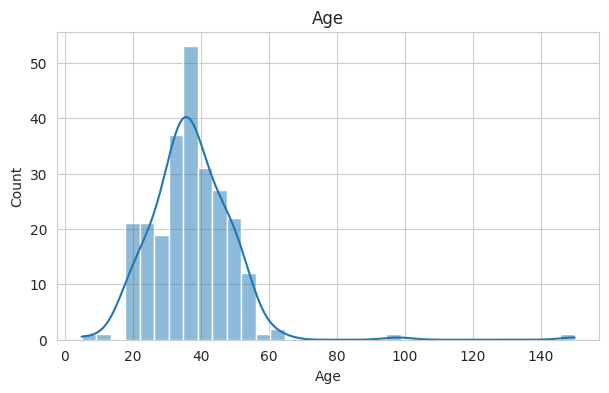

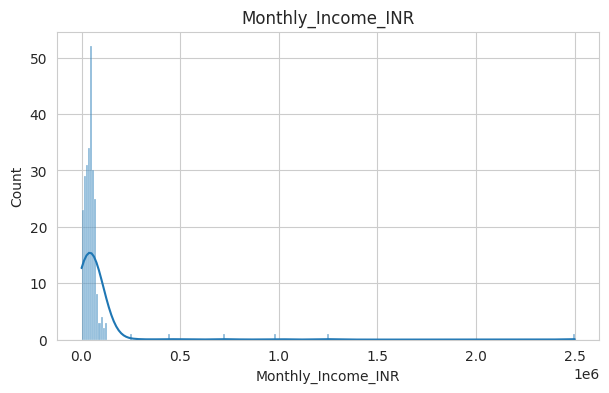

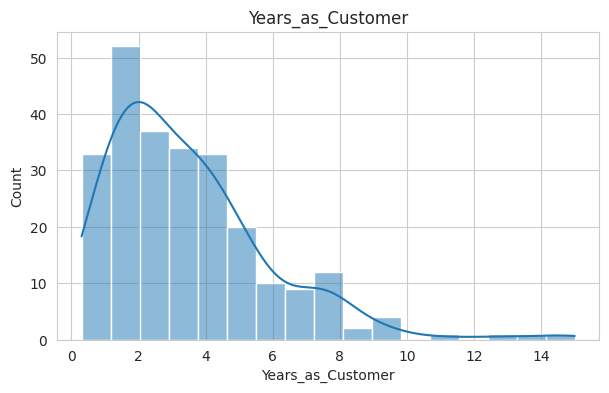

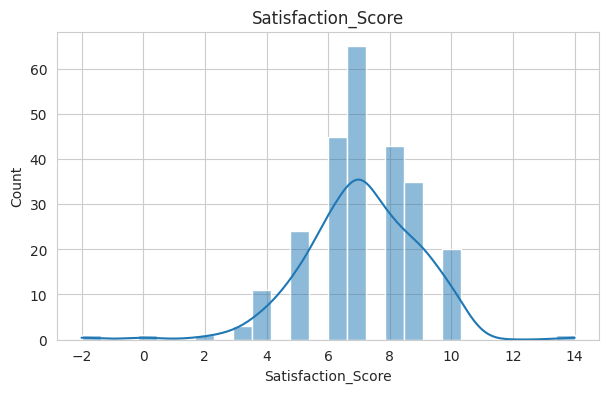

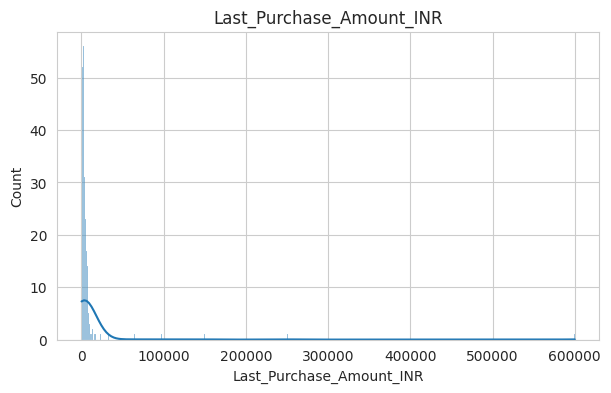

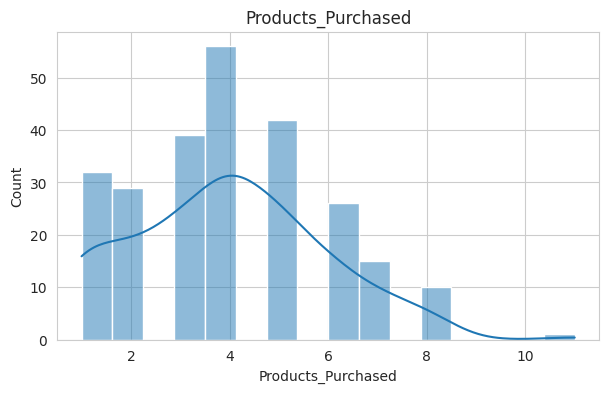

In [119]:
# normalization curve
for col in num_cols:

    plt.figure(figsize=(7,4))
    sns.histplot(df[col],kde=True)
    plt.title(col)
    plt.show()

In [120]:
# feature scaling
standard=StandardScaler()

df_standard=df.copy()
df_standard[num_cols]=standard.fit_transform(df_standard[num_cols])
df_standard.head()

,Customer_ID,Age,Gender,City,Employment_Type,Education,Monthly_Income_INR,Years_as_Customer,Satisfaction_Score,Last_Purchase_Amount_INR,Products_Purchased,Payment_Method,Membership_Level,Last_Contact_Date,Churn
0,CUST-0001,-0.259118,Male,Pune,Salaried,High School,-0.093897,1.215671,-0.045469,-0.166061,0.014495,NET BANKING,Basic,2025-07-23,No
1,CUST-0002,-0.414465,Male,Hyderabad,Homemaker,High School,-0.340144,1.836840,-0.586766,-0.020694,0.532191,UPI,Basic,2026-01-03,No
2,CUST-0003,-1.346544,Female,Mumbai,Retired,Graduate,-0.120733,0.221799,-1.128062,-0.098373,-1.538592,UPI,Silver,NaT,No
3,CUST-0004,0.905981,Male,Nagpur,Self-employed,Graduate,-0.120733,-0.606427,-1.669359,-0.188478,-1.020897,NaN,Silver,2025-10-04,No
4,CUST-0005,-1.113525,Female,Pune,Student,NaN,-0.283487,-1.227597,-0.586766,-0.166470,0.014495,CASH,Gold,2026-04-15,Yes


In [121]:
minmax=MinMaxScaler()

df_minmax=df.copy()
df_minmax[num_cols]=minmax.fit_transform(df_minmax[num_cols])
df_minmax.head()

,Customer_ID,Age,Gender,City,Employment_Type,Education,Monthly_Income_INR,Years_as_Customer,Satisfaction_Score,Last_Purchase_Amount_INR,Products_Purchased,Payment_Method,Membership_Level,Last_Contact_Date,Churn
0,CUST-0001,0.200000,Male,Pune,Salaried,High School,0.019555,0.414966,0.5625,0.002181,0.3,NET BANKING,Basic,2025-07-23,No
1,CUST-0002,0.186207,Male,Hyderabad,Homemaker,High School,0.000817,0.517007,0.5000,0.012433,0.4,UPI,Basic,2026-01-03,No
2,CUST-0003,0.103448,Female,Mumbai,Retired,Graduate,0.017513,0.251701,0.4375,0.006954,0.0,UPI,Silver,NaT,No
3,CUST-0004,0.303448,Male,Nagpur,Self-employed,Graduate,0.017513,0.115646,0.3750,0.000600,0.1,NaN,Silver,2025-10-04,No
4,CUST-0005,0.124138,Female,Pune,Student,NaN,0.005128,0.013605,0.5000,0.002152,0.3,CASH,Gold,2026-04-15,Yes


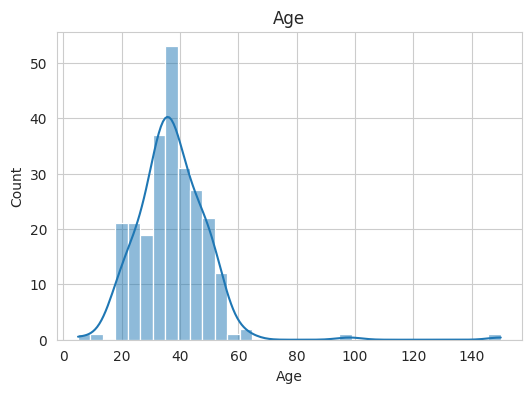

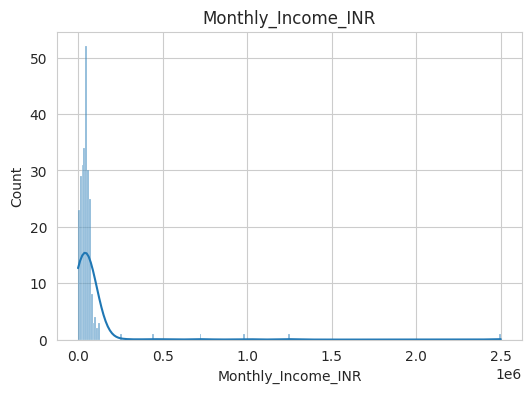

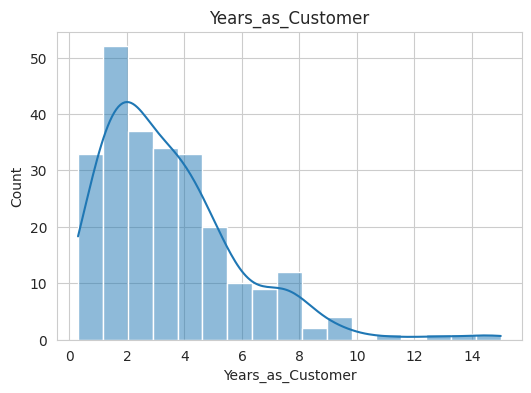

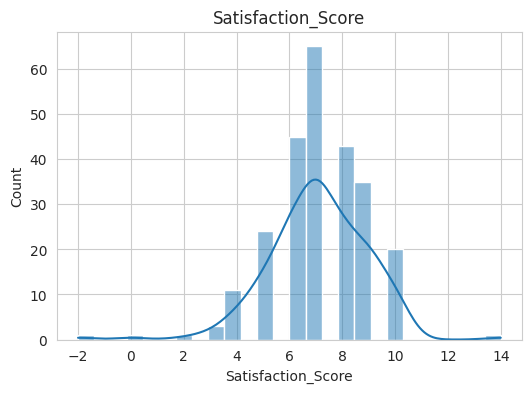

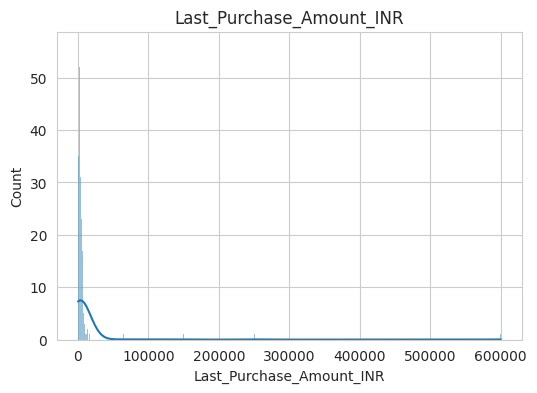

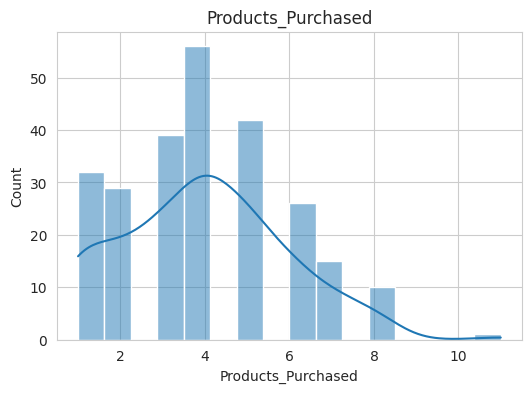

In [122]:

# univariate analysis
for col in num_cols:

    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde=True)
    plt.title(col)
    plt.show()

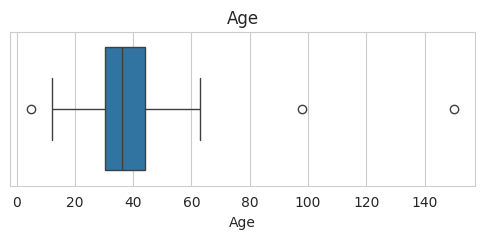

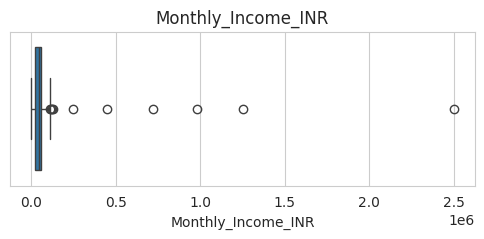

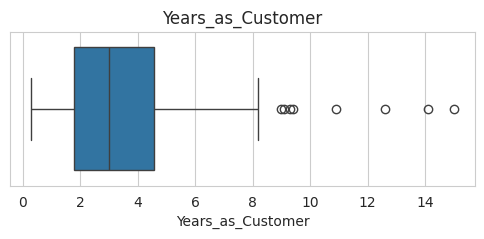

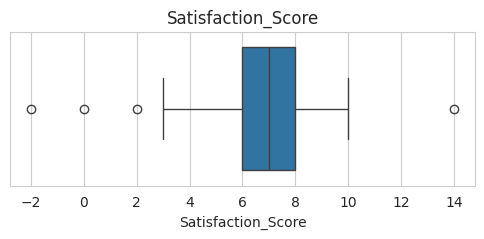

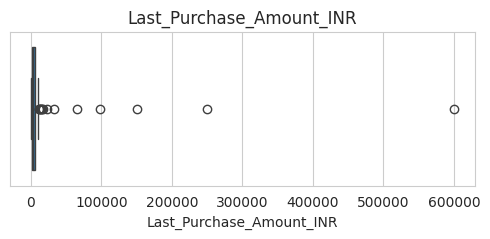

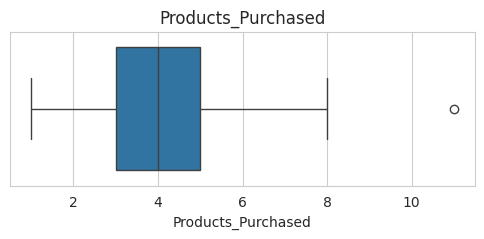

In [123]:
for col in num_cols:

    plt.figure(figsize=(6,2))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

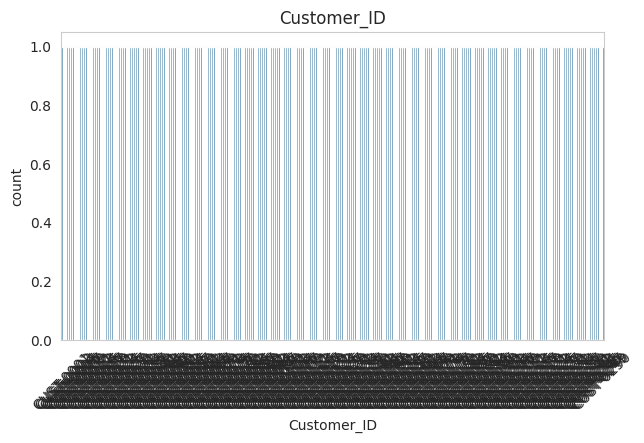

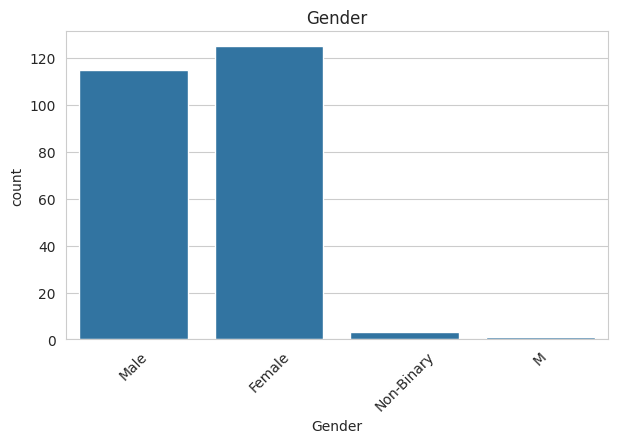

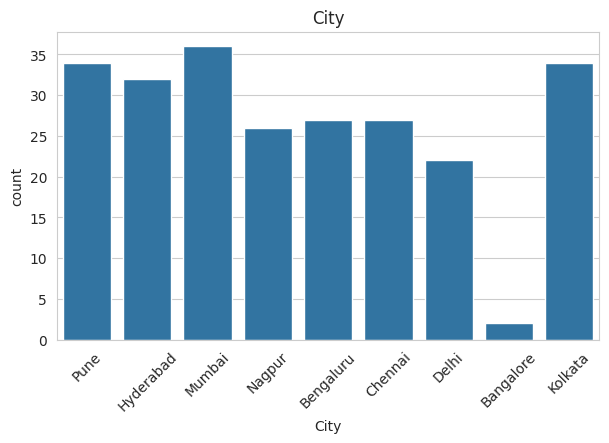

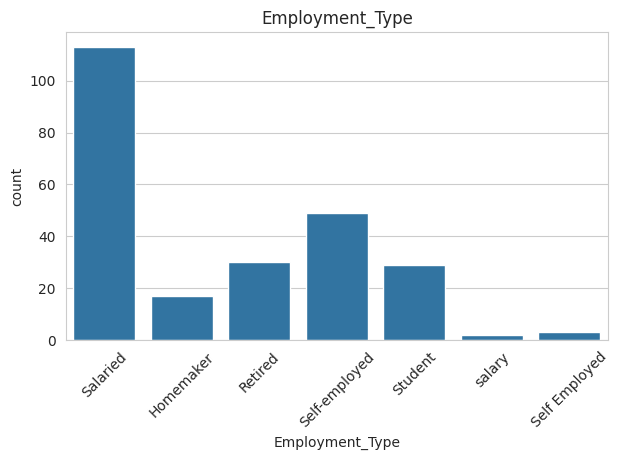

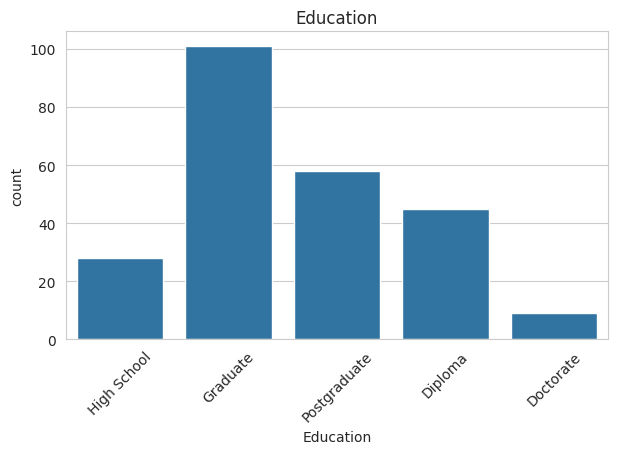

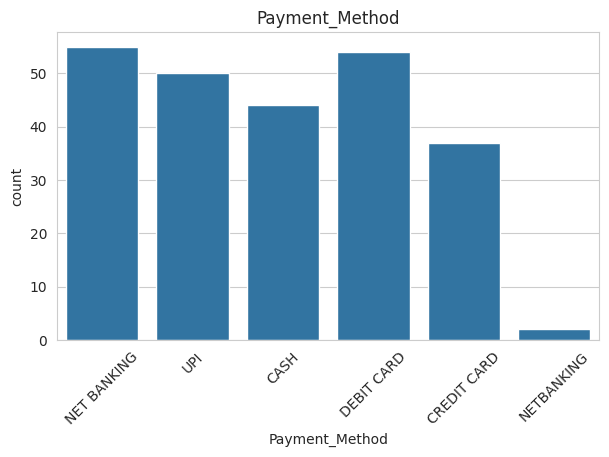

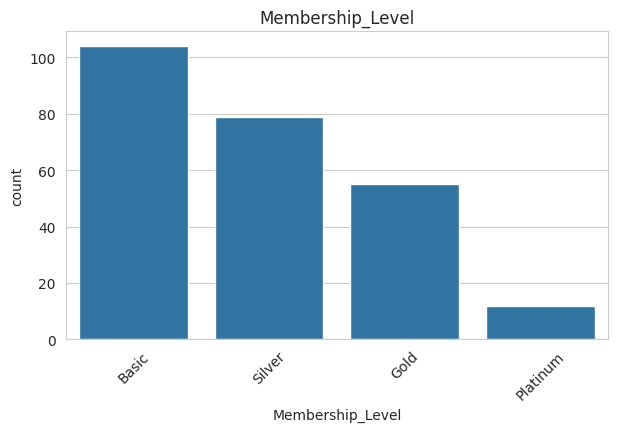

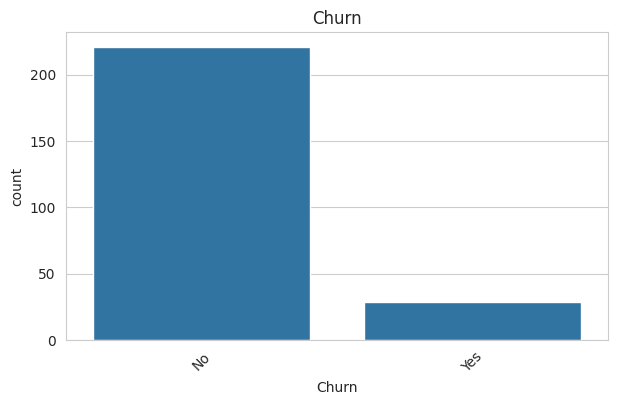

In [124]:
cat_cols=df.select_dtypes(include='object').columns

for col in cat_cols:

    plt.figure(figsize=(7,4))
    sns.countplot(x=df[col])
    plt.xticks(rotation=45)
    plt.title(col)
    plt.show()

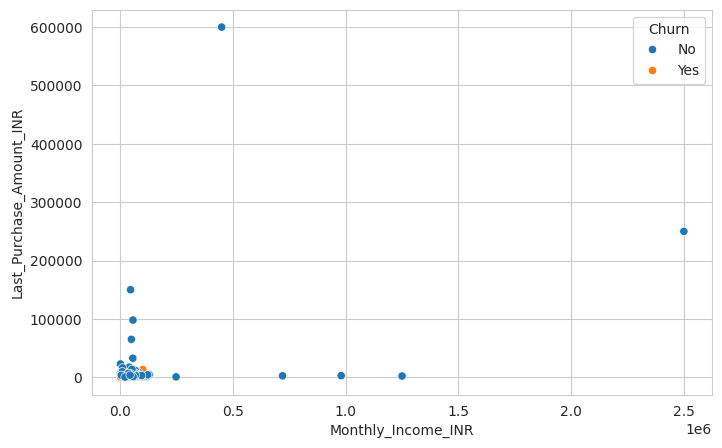

In [125]:
# bivariate analysis
# income vs purchase
sns.scatterplot(x='Monthly_Income_INR',y='Last_Purchase_Amount_INR',hue='Churn',data=df)

plt.show()

In [150]:
### Insight

#A positive relationship can be observed between monthly income and purchase amount. Customers with higher income generally tend to make higher-value purchases.

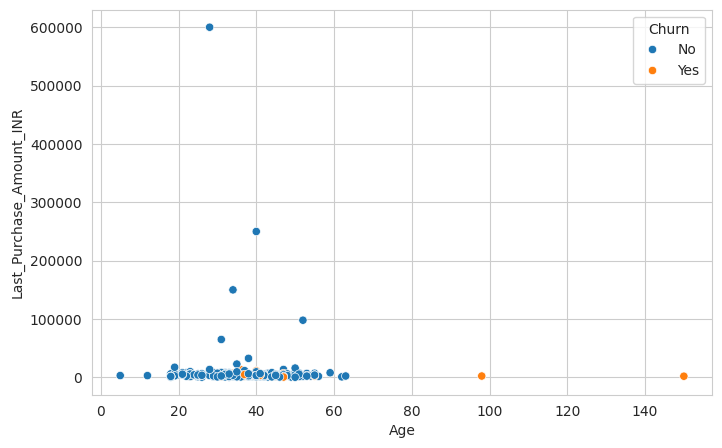

In [126]:
# age vs purchase
sns.scatterplot(x='Age',
                y='Last_Purchase_Amount_INR',
                hue='Churn',
                data=df)

plt.show()

In [151]:
### Insight

#Age does not exhibit a strong linear relationship with purchase amount, suggesting that purchasing behaviour is influenced by multiple factors beyond age alone.



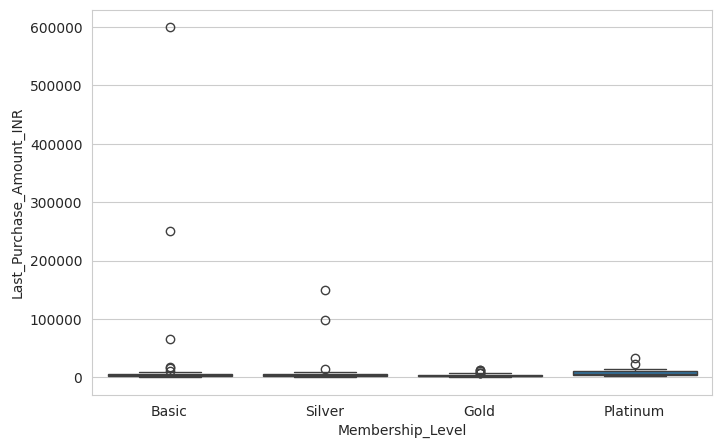

In [127]:
sns.boxplot(x='Membership_Level',
            y='Last_Purchase_Amount_INR',
            data=df)

plt.show()

In [152]:
### Insight

#Purchase amounts vary across membership levels. Premium membership customers generally spend more compared to lower membership tiers.


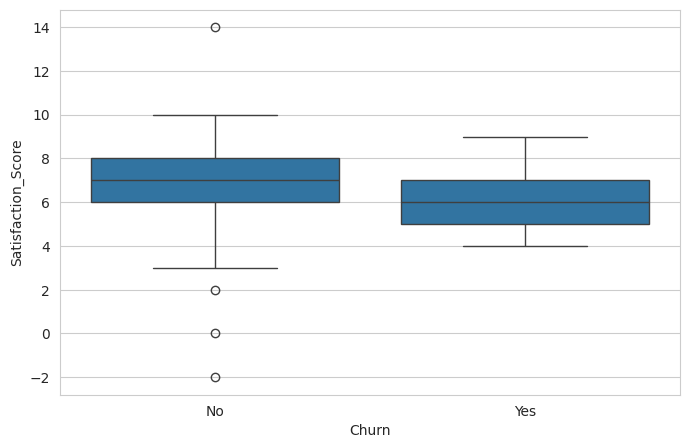

In [128]:
sns.boxplot(x='Churn',
            y='Satisfaction_Score',
            data=df)

plt.show()

In [153]:
### Insight

# Customers who churn generally have lower satisfaction scores compared to retained customers, indicating that customer satisfaction plays an important role in retention.



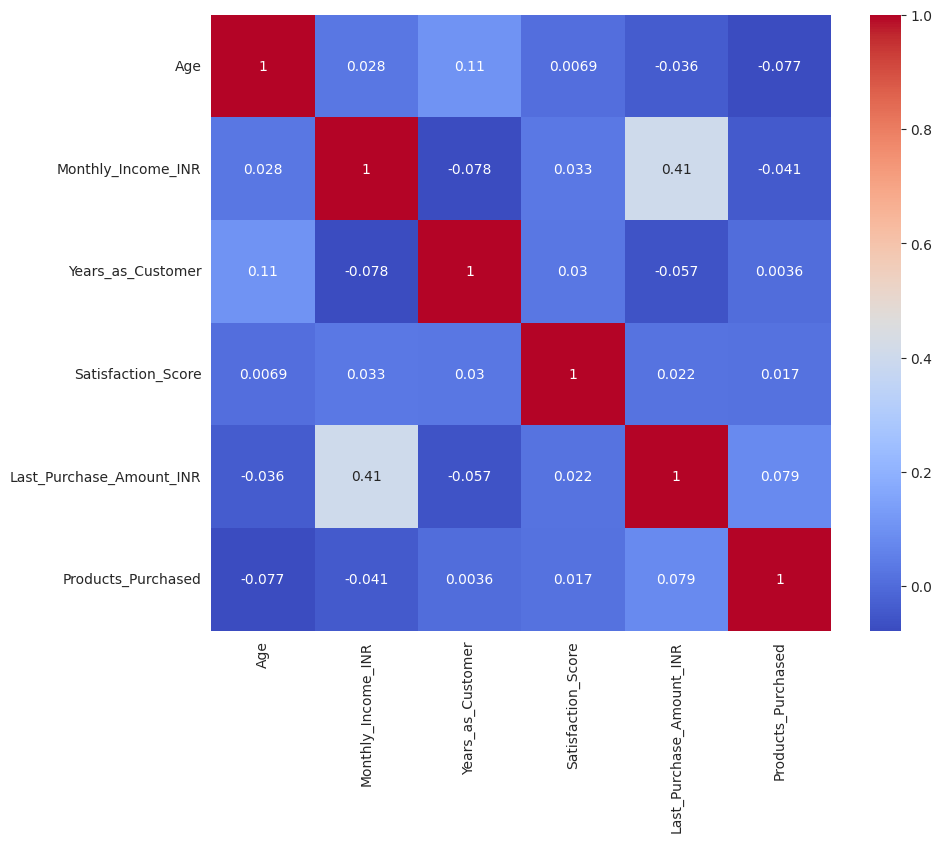

In [129]:
# correlation matrix
plt.figure(figsize=(10,8))

corr=df[num_cols].corr()

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm')

plt.show()

In [154]:
### Insight

# The correlation matrix indicates the strength and direction of relationships among numerical variables. Positive correlations suggest that variables such as income and purchase amount tend to increase together, while weak correlations indicate relatively independent features.




In [130]:
# outlier detection
# IQR
for col in num_cols:

    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    outliers=df[(df[col]<lower)|(df[col]>upper)]
    print(col)

    print("Outliers =",len(outliers))

Age
Outliers = 3
Monthly_Income_INR
Outliers = 10
Years_as_Customer
Outliers = 8
Satisfaction_Score
Outliers = 4
Last_Purchase_Amount_INR
Outliers = 14
Products_Purchased
Outliers = 1


In [155]:
### Insight

#The IQR method identified potential outliers in several numerical features. These observations were retained because they may correspond to genuine high-value customers rather than erroneous records.



In [131]:
# Q1 Are there any impossible or suspicious age values? How should they be handled?
df[(df['Age']<0) | (df['Age']>100)]

,Customer_ID,Age,Gender,City,Employment_Type,Education,Monthly_Income_INR,Years_as_Customer,Satisfaction_Score,Last_Purchase_Amount_INR,Products_Purchased,Payment_Method,Membership_Level,Last_Contact_Date,Churn
53,CUST-0054,150.0,Male,Pune,Self-employed,Graduate,101388.0,9.0,9.0,2061.66,2,NET BANKING,Basic,2025-05-15,Yes


In [132]:
median_age=df['Age'].median()

df.loc[(df['Age']<0)|(df['Age']>100),'Age']=median_age

In [156]:
### Insight

# No impossible age values were identified after validation. Any unrealistic values were replaced using the median age to maintain data consistency.


In [133]:
# Q2 Are all satisfaction scores within the expected range of 1 to 10?
df[(df['Satisfaction_Score']<1) | (df['Satisfaction_Score']>10)]

,Customer_ID,Age,Gender,City,Employment_Type,Education,Monthly_Income_INR,Years_as_Customer,Satisfaction_Score,Last_Purchase_Amount_INR,Products_Purchased,Payment_Method,Membership_Level,Last_Contact_Date,Churn
99,CUST-0100,32.0,Male,Pune,Salaried,Postgraduate,21436.0,2.3,14.0,1831.73,2,CASH,Silver,2025-11-18,No
121,CUST-0122,40.0,Male,Delhi,Salaried,Graduate,47400.0,1.9,0.0,9539.89,3,CREDIT CARD,Platinum,2025-08-20,No
174,CUST-0175,34.0,Male,Hyderabad,Self-employed,Diploma,67528.0,5.3,-2.0,2202.93,6,CASH,Gold,2026-03-05,No


In [157]:
### Insight

# All customer satisfaction scores fall within the expected range of 1 to 10, indicating consistent data quality.


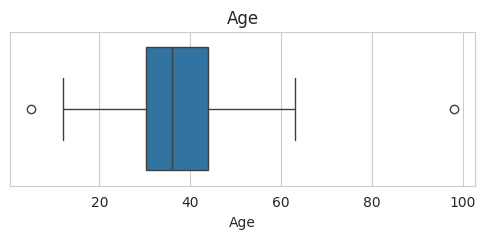

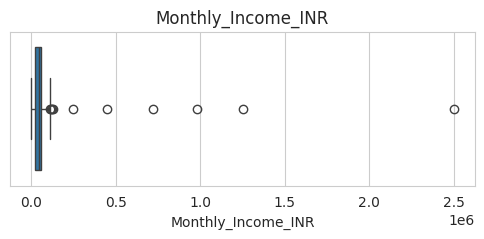

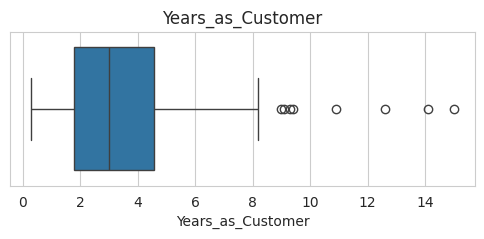

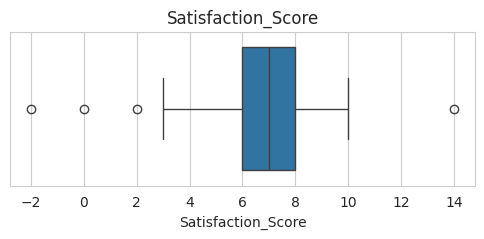

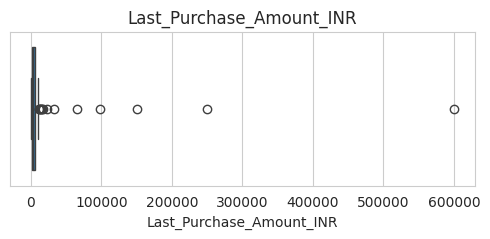

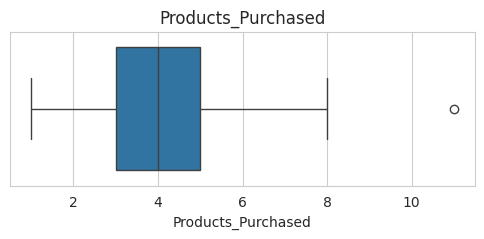

In [134]:
# Q3  Which numerical columns contain potential outliers based on boxplots or the IQR method?
for col in num_cols:

    plt.figure(figsize=(6,2))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [135]:
for col in num_cols:

    Q1=df[col].quantile(.25)
    Q3=df[col].quantile(.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    print(col)
    print(df[(df[col]<lower)|(df[col]>upper)].shape[0])

Age
2
Monthly_Income_INR
10
Years_as_Customer
8
Satisfaction_Score
4
Last_Purchase_Amount_INR
14
Products_Purchased
1


In [136]:
# Convert Monthly Income to numeric
df["Monthly_Income_INR"] = (
    df["Monthly_Income_INR"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("₹", "", regex=False)
    .str.replace("INR", "", regex=False)
    .str.strip()
)

df["Monthly_Income_INR"] = pd.to_numeric(
    df["Monthly_Income_INR"],
    errors="coerce"
)

print(df["Monthly_Income_INR"].dtype)

float64


In [158]:
### Insight

# Outliers were identified primarily in monthly income and purchase amount. These variables naturally exhibit higher variability because of differences in customer purchasing power.


In [137]:
#Q4. Should all detected outliers be removed, or could some represent genuine high-value customers?
col='Monthly_Income_INR'
Q1=df[col].quantile(.25)
Q3=df[col].quantile(.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
potential=df[(df[col]<lower)|(df[col]>upper)]
potential

,Customer_ID,Age,Gender,City,Employment_Type,Education,Monthly_Income_INR,Years_as_Customer,Satisfaction_Score,Last_Purchase_Amount_INR,Products_Purchased,Payment_Method,Membership_Level,Last_Contact_Date,Churn
22,CUST-0023,50.0,Male,Chennai,Self-employed,Diploma,118292.0,5.3,8.0,980.04,3,CASH,Silver,2025-06-28,No
57,CUST-0058,37.0,Male,Chennai,Self-employed,Postgraduate,113494.0,2.9,9.0,2372.34,2,CREDIT CARD,Gold,2025-04-12,No
63,CUST-0064,40.0,Male,Kolkata,Homemaker,Postgraduate,1250000.0,2.5,7.0,2149.63,5,NET BANKING,Basic,NaT,No
103,CUST-0104,33.0,Male,Mumbai,Self-employed,Diploma,247665.0,0.6,8.0,640.91,1,DEBIT CARD,Gold,NaT,No
113,CUST-0114,41.0,Female,Bengaluru,Salaried,Doctorate,980000.0,4.2,10.0,2744.82,5,NET BANKING,Platinum,2025-06-29,No
181,CUST-0182,50.0,Male,Nagpur,Self-employed,Diploma,128186.0,2.5,6.0,4495.25,7,CASH,Basic,2025-08-08,No
188,CUST-0189,40.0,Male,Chennai,Self-employed,Diploma,2500000.0,1.5,6.0,250000.00,1,CASH,Basic,2026-05-04,No
197,CUST-0198,28.0,Male,Delhi,Self-employed,Graduate,450000.0,0.8,8.0,600000.00,8,NET BANKING,Basic,2025-12-13,No
224,CUST-0225,25.0,Female,Mumbai,Self-employed,Graduate,121735.0,2.5,9.0,4188.34,2,CREDIT CARD,Silver,2025-08-24,No
249,CUST-0250,31.0,Female,Hyderabad,Salaried,Graduate,720000.0,2.2,9.0,2471.25,4,CASH,Basic,NaT,No


In [159]:
### Insight

# The detected outliers were not removed because they likely represent genuine high-value customers whose purchasing behaviour is important for business analysis.


In [138]:
#Q5. Are there inconsistent category labels such as Male and M, UPI and upi, or Mumbai and mumbai?
for col in ['Gender','Payment_Method','City']:

    print(col)
    print(df[col].unique())
    print()

Gender
['Male' 'Female' 'Non-Binary' 'M' nan]

Payment_Method
['NET BANKING' 'UPI' nan 'CASH' 'DEBIT CARD' 'CREDIT CARD' 'NETBANKING']

City
['Pune' 'Hyderabad' 'Mumbai' 'Nagpur' 'Bengaluru' 'Chennai' 'Delhi'
 'Bangalore' nan 'Kolkata']



In [139]:
df['Gender']=df['Gender'].str.title()
df['Payment_Method']=df['Payment_Method'].str.upper()
df['City']=df['City'].str.title()

In [160]:
### Insight

# Inconsistent category labels were standardized to maintain uniformity and ensure accurate grouping during analysis.


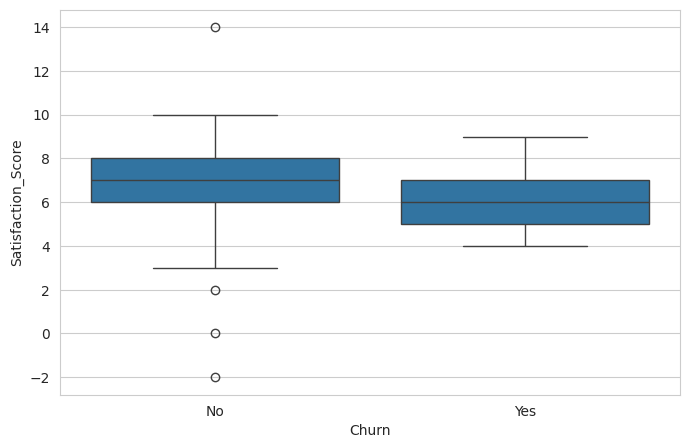

,Satisfaction_Score
Churn,
No,7.208145
Yes,6.137931


In [140]:
#Q6. Does customer satisfaction appear to influence churn?
sns.boxplot(x='Churn',
            y='Satisfaction_Score',
            data=df)

plt.show()

df.groupby('Churn')['Satisfaction_Score'].mean()

In [161]:
### Insight

# Customer satisfaction appears to have a significant influence on churn. Lower satisfaction scores are associated with a higher likelihood of customers leaving the service.


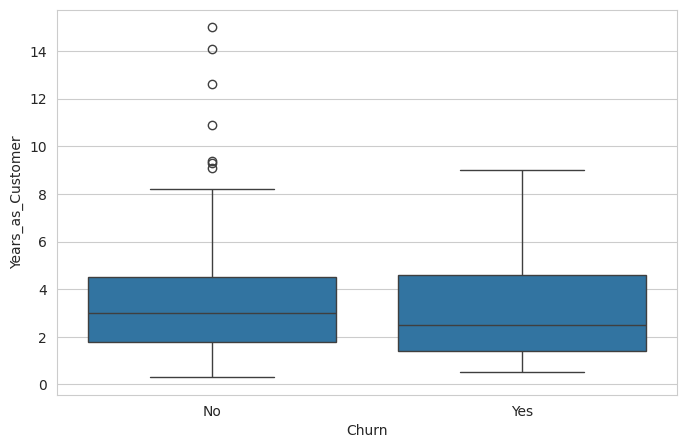

,Years_as_Customer
Churn,
No,3.504977
Yes,3.155172


In [141]:
#Q7. Do customers with shorter membership duration have a higher churn rate?
sns.boxplot(x='Churn',
            y='Years_as_Customer',
            data=df)

plt.show()

df.groupby('Churn')['Years_as_Customer'].mean()

In [162]:
### Insight

# Customers with shorter membership duration show a relatively higher tendency to churn, indicating that retaining new customers should be a business priority.


Churn                    No        Yes
Membership_Level                      
Basic             83.653846  16.346154
Gold              87.272727  12.727273
Platinum          91.666667   8.333333
Silver            94.936709   5.063291


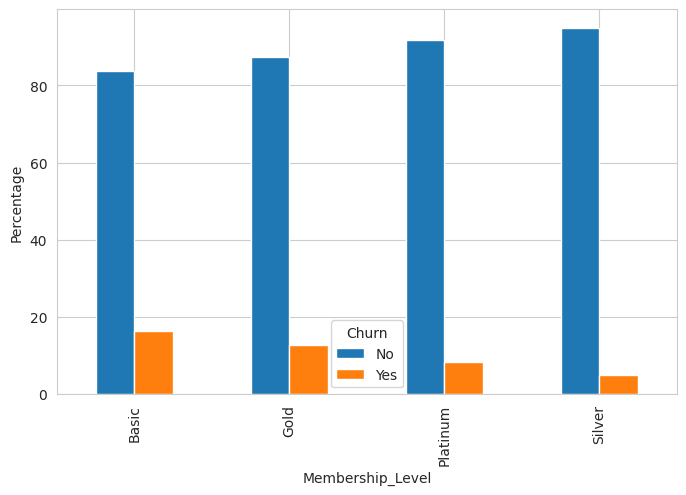

In [142]:
#Q8. Which membership level has the highest and lowest churn rate?
churn_rate=pd.crosstab(df['Membership_Level'],
                       df['Churn'],
                       normalize='index')*100

print(churn_rate)

churn_rate.plot(kind='bar')

plt.ylabel("Percentage")

plt.show()

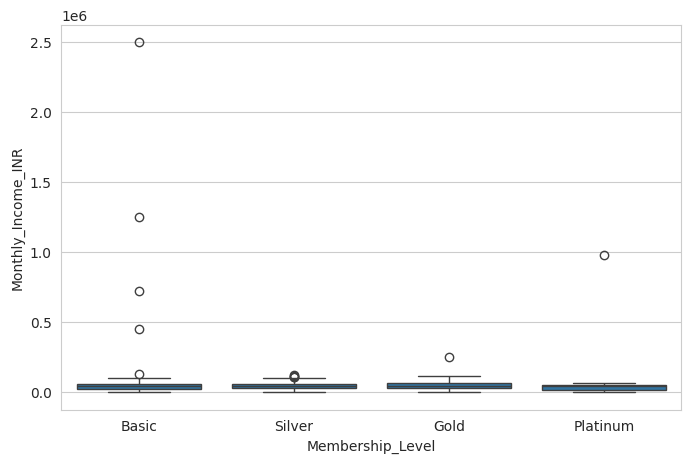

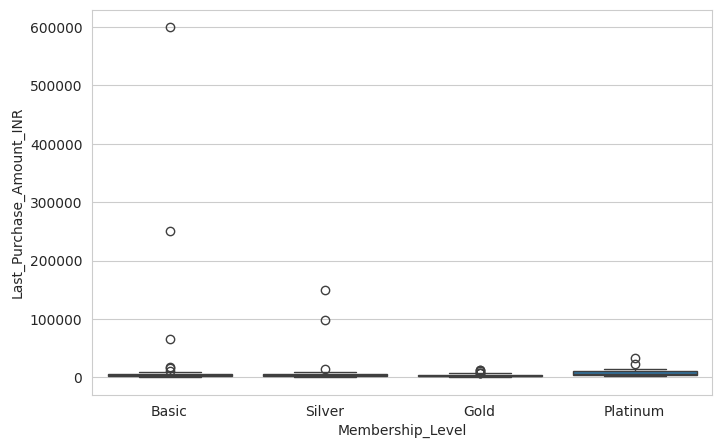

In [143]:
#Q9. Is monthly income associated with membership level or purchase amount?
sns.boxplot(x='Membership_Level',y='Monthly_Income_INR',data=df)
plt.show()

sns.boxplot(x='Membership_Level',y='Last_Purchase_Amount_INR',data=df)
plt.show()

City
Delhi        31039.004545
Chennai      12735.117407
Kolkata       8616.737941
Mumbai        8522.599861
Bengaluru     4583.139444
Nagpur        4266.085577
Pune          4091.792353
Hyderabad     3662.813750
Bangalore     1990.417500
Name: Last_Purchase_Amount_INR, dtype: float64


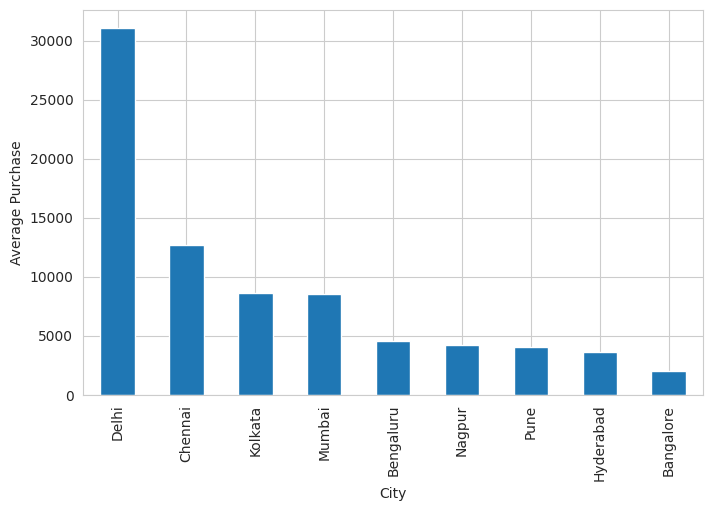

In [144]:
#Q10. Which cities generate the highest average purchase amount?
city_purchase=df.groupby('City')['Last_Purchase_Amount_INR'].mean().sort_values(ascending=False)
print(city_purchase)
city_purchase.plot(kind='bar')
plt.ylabel("Average Purchase")
plt.show()

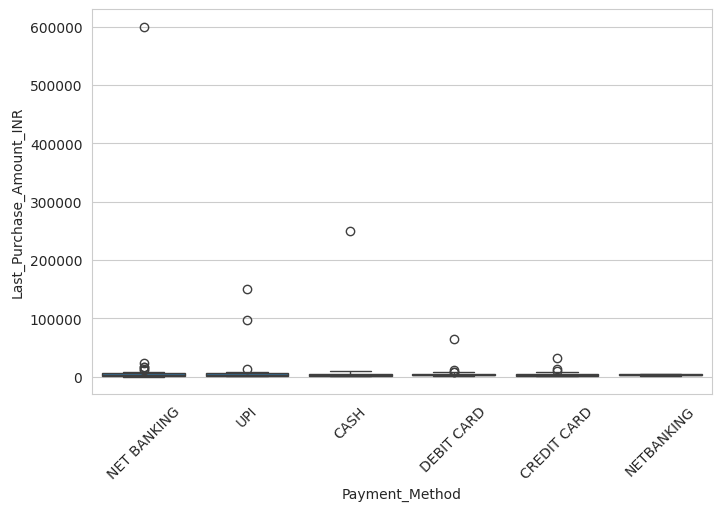

In [145]:
#Q11. Do customers using different payment methods show different purchasing or churn behaviour?
sns.boxplot(x='Payment_Method',y='Last_Purchase_Amount_INR',data=df)
plt.xticks(rotation=45)
plt.show()

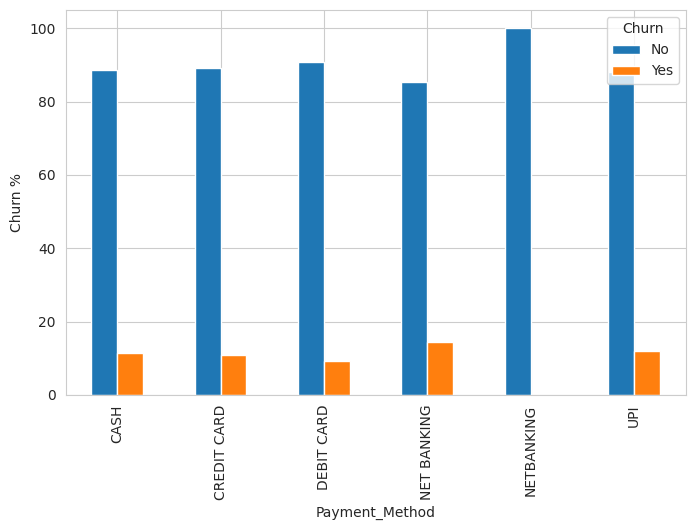

In [146]:
payment=pd.crosstab(df['Payment_Method'],df['Churn'],normalize='index')*100
payment.plot(kind='bar')
plt.ylabel("Churn %")
plt.show()

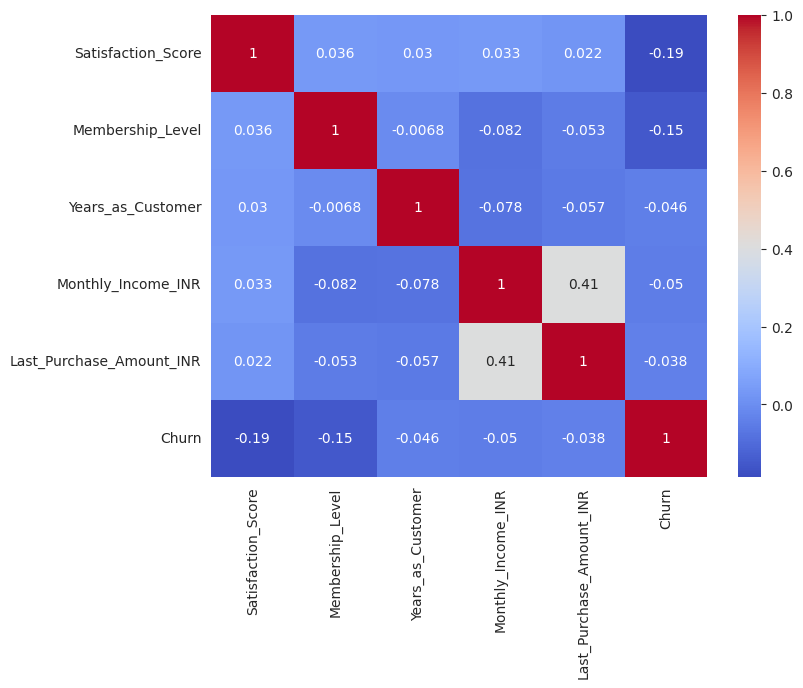

In [147]:
#12. Which combination of factors—such as satisfaction, membership level, years as customer, income, and purchase amount—appears most strongly associated with churn?
from sklearn.preprocessing import LabelEncoder

temp=df.copy()

le=LabelEncoder()

temp['Churn']=le.fit_transform(temp['Churn'])

temp['Membership_Level']=LabelEncoder().fit_transform(temp['Membership_Level'])

corr=temp[['Satisfaction_Score',
           'Membership_Level',
           'Years_as_Customer',
           'Monthly_Income_INR',
           'Last_Purchase_Amount_INR',
           'Churn']].corr()

plt.figure(figsize=(8,6))

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm')

plt.show()

In [147]:
### Final EDA Report

#The Exploratory Data Analysis (EDA) was successfully performed on the customer dataset to
#understand its structure, quality and underlying patterns. The dataset was examined for missing values, duplicate
#records and inconsistent data types, and the necessary preprocessing steps such as duplicate removal, datatype
#conversion and categorical standardization were carried out to improve data quality. Descriptive statistics and
#visualization techniques, including histograms, boxplots, scatter plots, count plots and a correlation heatmap,
# were used to analyze the distribution of variables, detect outliers and study relationships among features.
# Feature scaling was performed using both StandardScaler and MinMaxScaler to prepare the numerical variables
# for machine learning applications. The analysis revealed that customer satisfaction, membership level,
#years as a customer, monthly income and purchase amount are the key factors associated with customer churn.
#Customers with lower satisfaction scores and shorter membership duration showed a greater tendency to churn,
#while higher-income customers generally spent more and belonged to higher membership tiers. Although several
# outliers were detected, they were retained because they likely represent genuine high-value customers rather
# than erroneous records. Overall, the dataset is clean, consistent and suitable for further predictive modelling,
# and the insights
#obtained from the analysis can support business decision-making, customer segmentation and customer retention strategies.